In [15]:
%pip install numpy  # install the libraries into this notebook's Python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


In [16]:
%pip install pandas 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import numpy as np #NumPy for the maths (compound annual rate)
import pandas as pd #Pandas to read and organize the data
import matplotlib.pyplot as plt #Matplotlib to draw the graph

In [19]:
inflation = pd.read_csv('STATIC_INFLATIONCALC.csv', skiprows=8)
display(inflation)

,date,STATIC_INFLATIONCALC
0,1914-01-01,6.0
1,1914-02-01,6.0
2,1914-03-01,6.0
3,1914-04-01,6.0
4,1914-05-01,5.9
...,...,...
1350,2026-05-01,169.6
1351,2026-06-01,169.0
1352,2026-07-01,169.9
1353,2026-08-01,169.8


In [20]:
inflation.columns = ['date', 'CPI']
inflation['date'] = pd.to_datetime(inflation['date']) #change the dates from text to dates
inflation['change'] = inflation['CPI'].pct_change(12) * 100 #annual % change

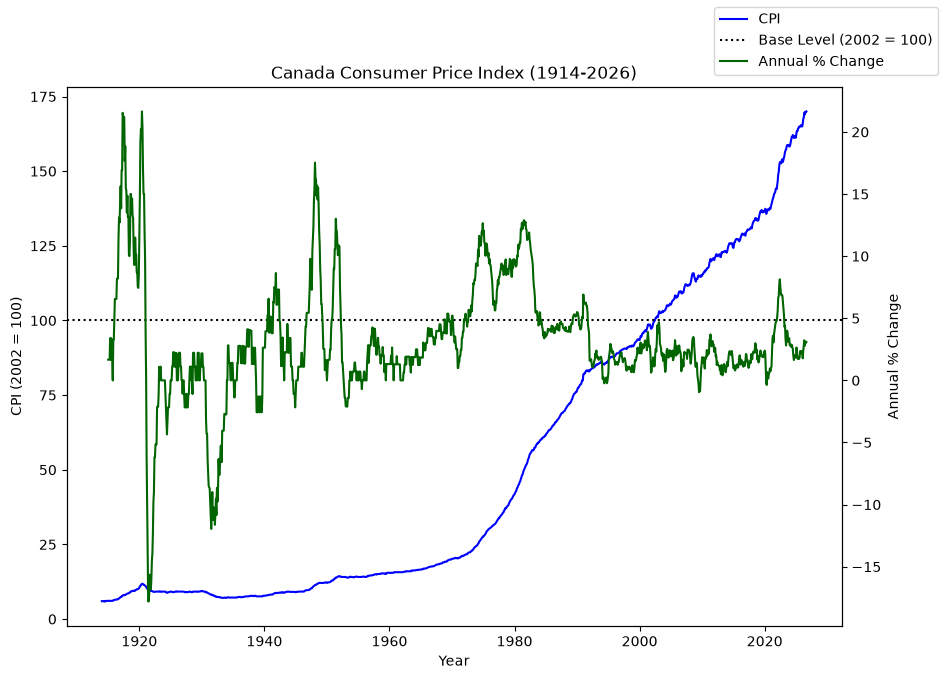

In [21]:
fig, ax = plt.subplots(figsize=(10,7))

ax.plot(inflation['date'], inflation['CPI'], color='blue', label='CPI')
ax.axhline(100, color='black', linestyle=':', label='Base Level (2002 = 100)')
ax.set_xlabel('Year')
ax.set_ylabel('CPI (2002 = 100)')

ax2 = ax.twinx() #right side axis
ax2.plot(inflation['date'], inflation['change'], color='darkgreen', label='Annual % Change')
ax2.set_ylabel('Annual % Change') #axis label

ax.set_title('Canada Consumer Price Index (1914-2026)') # graph title

fig.legend() #gives legend for graph

plt.savefig('cpi_graph.png')
plt.show() # display the graph

In [22]:
price = 0
while True: #keep asking until the price is a number above 0
    price = input('Price of goods or services: $')
    if price.replace('.', '', 1).isnumeric(): #take out the decimal point, then check it is only numbers
        price = float(price) #text to a number
        if price > 0:
            break
        print('The price has to be more than $0, please try again')
    else:
        print('That is not a number, please try again')

That is not a number, please try again


In [23]:
dates = list(inflation['date'].astype(str).str[:7]) #keep only the YYYY-MM part of each date

while True: #keep asking until the first date is in the data
    date1 = input('First date (YYYY-MM): ') #asks for first date
    if date1 in dates: #if this date in the data, stop the loop and move on
        break
    print('Please enter a date as YYYY-MM between 1914-01 and 2026-09')

while True: #keep asking until the second date is in the data
    date2 = input('Second date (YYYY-MM): ') #asks for second date
    if date2 in dates: #if this date in the data, stop the loop and move on
        break
    print('Please enter a date as YYYY-MM between 1914-01 and 2026-09')

In [24]:
year1 = int(date1[:4]) #first 4 characters are the year
month1 = int(date1[5:]) #last 2 characters are the month
year2 = int(date2[:4])
month2 = int(date2[5:])

cpi1 = inflation['CPI'].iloc[dates.index(date1)] #CPI for the first date
cpi2 = inflation['CPI'].iloc[dates.index(date2)] #CPI for the second date

new_price = price * (cpi2 / cpi1) #Cost2 = Cost1 * (CPI2 / CPI1)
percent_change = (new_price - price) / price * 100 #%Change = (Cost2 - Cost1) / Cost1 * 100
years = (year2 - year1) + (month2 - month1) / 12 #number of years between the dates
annual_rate = ((cpi2 / cpi1) ** (1 / years) - 1) * 100 #average yearly inflation

In [25]:
print('A basket of goods and services that cost: $', price, 'in', date1, 'would cost: $', round(new_price, 2), 'in', date2)
print('Percent change:', round(percent_change, 2))
print('Number of years:', round(years, 2))
print('Average annual rate of inflation (%):', round(annual_rate, 2))
print('CPI for first date: (', date1, ')', cpi1)
print('CPI for second date: (', date2, ')', cpi2)

A basket of goods and services that cost: $ 100.0 in 2000-01 would cost: $ 176.47 in 2026-01
Percent change: 76.47
Number of years: 26.0
Average annual rate of inflation (%): 2.21
CPI for first date: ( 2000-01 ) 93.5
CPI for second date: ( 2026-01 ) 165.0
